# Unit 4 · Natural Language & Conversational Visualization — Case-Based Activity
**Case:** *Auditing ChatViz at RideNow*

RideNow is a ride-hailing company. Its operations team has piloted **ChatViz**, a chat assistant that turns plain-language questions into charts and lets analysts keep refining them in conversation.
Before it goes to every analyst, you have been asked to **audit** it: how it reads a question, how it handles follow-ups, how it generates and validates chart specifications, how it edits charts, and what goes wrong.

**How to work**
* Run the cells from top to bottom. Do **not** edit the setup cell.
* Wherever you see `# TODO`, replace the placeholder (`None` or `""`) with your answer or code.
* Written answers: two or three sentences, using ideas from the lecture.

In [1]:
import math, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 20, "display.width", 140, "display.max_colwidth", 90)

In [2]:
# ---------------- mini Vega-Lite-style renderer (do not edit) ----------------
import copy, json, difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
ACCENT, GREY, BLUE = "#E8710A", "#BDBDBD", "#4C72B0"

def apply_filters(df, spec):
    for t in spec.get("transform", []):
        f = t.get("filter")
        if not f:
            continue
        if "equal" in f:
            df = df[df[f["field"]] == f["equal"]]
        elif "oneOf" in f:
            df = df[df[f["field"]].isin(f["oneOf"])]
    return df

def is_horizontal(spec):
    e = spec["encoding"]
    return spec["mark"] == "bar" and e["x"].get("type") == "quantitative" and e["y"].get("type") in ("nominal", "ordinal")

def compute(spec, df):
    """Return the tidy table that the chart plots (used for drawing AND for checking values)."""
    enc, mark = spec["encoding"], spec["mark"]
    d = apply_filters(df, spec)
    x, y, c = enc["x"], enc["y"], enc.get("color", {})
    sf = c.get("field")
    if mark == "point":
        return d[[x["field"], y["field"]] + ([sf] if sf else [])].copy()
    if x.get("bin"):
        return d[[x["field"]]].copy()
    cat, val = (y, x) if is_horizontal(spec) else (x, y)
    agg = val.get("aggregate", "mean")
    keys = [cat["field"]] + ([sf] if sf else [])
    out = d.groupby(keys).size().rename("value") if agg == "count" else d.groupby(keys)[val["field"]].agg(agg).rename("value")
    return out.reset_index()

def _order(labels, field, sort, totals):
    labels = list(dict.fromkeys(labels))
    if sort in ("-y", "-x"):
        return sorted(labels, key=lambda l: -totals[l])
    if sort in ("y", "x"):
        return sorted(labels, key=lambda l: totals[l])
    if field == "month":
        return sorted(labels, key=MONTHS.index)
    return sorted(labels)

def render_spec(spec, df, ax=None, figsize=(6, 3.4)):
    enc, mark = spec["encoding"], spec["mark"]
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    t = compute(spec, df)
    x, y, c = enc["x"], enc["y"], enc.get("color", {})
    sf = c.get("field")
    if mark == "point":
        if sf:
            for k, g in t.groupby(sf):
                ax.scatter(g[x["field"]], g[y["field"]], s=10, alpha=.6, label=str(k))
            ax.legend(fontsize=7, title=sf, title_fontsize=7)
        else:
            ax.scatter(t[x["field"]], t[y["field"]], s=10, alpha=.5, color=BLUE)
        ax.set_xlabel(x.get("title", x["field"])); ax.set_ylabel(y.get("title", y["field"]))
    elif x.get("bin"):
        ax.hist(t[x["field"]], bins=25, color=BLUE)
        ax.set_xlabel(x.get("title", x["field"])); ax.set_ylabel(y.get("title", "count"))
    else:
        horiz = is_horizontal(spec)
        cat, val = (y, x) if horiz else (x, y)
        cf = cat["field"]
        tot = t.groupby(cf)["value"].sum()
        labels = _order(t[cf], cf, cat.get("sort"), tot)
        idx = np.arange(len(labels))
        series = sorted(t[sf].unique()) if sf else [None]
        for j, s in enumerate(series):
            g = t if s is None else t[t[sf] == s]
            vals = g.set_index(cf)["value"].reindex(labels).values
            if mark == "bar":
                w = 0.8 / len(series)
                pos = idx + (j - (len(series) - 1) / 2) * w
                colors = BLUE
                cond = c.get("condition")
                if s is None and cond:
                    colors = [ACCENT if l == cond["equal"] else c.get("value", GREY) for l in labels]
                (ax.barh if horiz else ax.bar)(pos, vals, w * 0.95, color=colors, label=None if s is None else str(s))
            else:
                ax.plot(idx, vals, marker="o", ms=3, label=None if s is None else str(s))
        (ax.set_yticks if horiz else ax.set_xticks)(idx)
        (ax.set_yticklabels if horiz else ax.set_xticklabels)(labels, fontsize=8)
        if horiz: ax.invert_yaxis()
        vtitle = val.get("title") or f"{val.get('aggregate', 'mean')}({val['field']})"
        ctitle = cat.get("title") or cat["field"]
        (ax.set_ylabel if not horiz else ax.set_xlabel)(vtitle)
        (ax.set_xlabel if not horiz else ax.set_ylabel)(ctitle)
        sc = val.get("scale", {})
        if sc.get("type") == "log":
            (ax.set_xscale if horiz else ax.set_yscale)("log")
        if mark == "bar" and sc.get("zero") is False:
            lo = t["value"].min() * 0.96
            (ax.set_xlim if horiz else ax.set_ylim)(lo, t["value"].max() * 1.02)
        if sf:
            ax.legend(fontsize=7, title=sf, title_fontsize=7)
    ax.set_title(spec.get("title", ""), fontsize=10, fontweight="bold", loc="left")
    return ax

def show_specs(specs, df, ncols=3, w=4.6, h=3.3):
    n = len(specs); nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, h * nrows), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, s in zip(axes.ravel(), specs):
        ax.axis("on"); render_spec(s, df, ax=ax)
    plt.tight_layout(); plt.show()

In [3]:
# ---------------- synthetic RideNow trips (do not edit) ----------------
rng = np.random.default_rng(21)
n = 1200
city = rng.choice(["Bengaluru", "Hyderabad", "Chennai", "Pune"], n, p=[.38, .27, .20, .15])
vehicle = rng.choice(["Auto", "Mini", "Sedan", "Bike"], n, p=[.30, .35, .20, .15])
year = rng.choice([2024, 2025], n)
month = rng.choice(MONTHS, n)
distance = np.clip(rng.gamma(2.4, 2.6, n), 0.8, 30).round(1)
mult = {"Auto": 9, "Mini": 11, "Sedan": 14, "Bike": 6}
city_f = {"Bengaluru": 1.10, "Hyderabad": 1.00, "Chennai": 0.95, "Pune": 1.05}
fare = (35 + distance * np.array([mult[v] for v in vehicle]) * np.array([city_f[c] for c in city]) * rng.normal(1, .06, n)).round(0)
wait = np.clip(rng.gamma(2.2, 2.0, n) + (city == "Bengaluru") * 2.5, 0.5, None).round(1)
cancel_p = np.clip(0.03 + 0.004 * wait + (city == "Chennai") * 0.012 - (city == "Pune") * 0.01, 0.005, None)

df = pd.DataFrame({
    "city": city, "year": year, "month": month, "vehicle_type": vehicle, "distance_km": distance, "fare": fare, "wait_min": wait,
    "driver_rating": np.clip(rng.normal(4.4, .35, n) - 0.02 * wait, 1, 5).round(1),
    "payment_mode": rng.choice(["UPI", "Cash", "Card", "Wallet"], n, p=[.55, .20, .15, .10]),
    "cancelled": (rng.random(n) < cancel_p).astype(int),
})

# helpers used later (do not edit)
def spec_diff(a, b):
    def flat(d, p=""):
        out = {}
        for k, v in d.items():
            q = f"{p}.{k}" if p else k
            out.update(flat(v, q) if isinstance(v, dict) else {q: str(v)})
        return out
    fa, fb = flat(a), flat(b)
    return sorted(k for k in set(fa) | set(fb) if fa.get(k) != fb.get(k))

def lint_chart(spec):
    issues, t = [], spec.get("title", "").strip().lower()
    if not t: issues.append("no title")
    if re.match(r"^(this|the) (chart|figure|graph|plot) (shows|displays|presents)", t): issues.append("title describes the chart instead of asserting the point")
    for ch in ("x", "y"):
        e = spec["encoding"].get(ch, {})
        if e.get("type") == "quantitative" and "title" not in e: issues.append(f"{ch}-axis has no title with units")
    return issues or ["OK"]

df.head()

,city,year,month,vehicle_type,distance_km,fare,wait_min,driver_rating,payment_mode,cancelled
0,Chennai,2025,Sep,Bike,4.8,59.0,2.3,5.0,UPI,0
1,Hyderabad,2024,Aug,Auto,9.9,122.0,4.7,4.5,Card,0
2,Chennai,2025,Aug,Mini,3.1,65.0,8.1,4.0,UPI,0
3,Bengaluru,2024,Sep,Mini,2.6,64.0,6.5,4.8,UPI,0
4,Hyderabad,2024,Sep,Mini,3.5,77.0,3.0,4.7,Cash,0


---
## Case 1 · How does ChatViz *read* a question? (NL2Vis, query → task abstraction, semantic parsing, ambiguity)
### 1a · From words to abstract tasks
Seven questions came in on the first day. For each one, name the **abstract task** ChatViz should infer.
Use exactly one of: `"trend"`, `"compare"`, `"extremes"`, `"distribution"`, `"correlation"`, `"part-to-whole"`, `"outliers"`.

In [4]:
questions = {
    "Q1": "How did the number of rides change month by month in 2025?",
    "Q2": "Compare average fare across cities",
    "Q3": "Does fare depend on distance?",
    "Q4": "Which 2 cities had the highest cancellation rate?",
    "Q5": "How spread out are the driver ratings?",
    "Q6": "What percentage of rides are paid by UPI?",
    "Q7": "Compare auto and sedan fares over the last 2 years",
}
TASKS = ["trend", "compare", "extremes", "distribution", "correlation", "part-to-whole", "outliers"]
DEFAULT_CHART = {"trend": "line chart", "compare": "sorted bar chart", "extremes": "sorted bar, top-k highlighted", "distribution": "histogram / boxplot",
                 "correlation": "scatter plot", "part-to-whole": "stacked bar (few parts)", "outliers": "scatter / line with highlights"}
pd.Series(questions, name="question").to_frame()

,question
Q1,How did the number of rides change month by month in 2025?
Q2,Compare average fare across cities
Q3,Does fare depend on distance?
Q4,Which 2 cities had the highest cancellation rate?
Q5,How spread out are the driver ratings?
Q6,What percentage of rides are paid by UPI?
Q7,Compare auto and sedan fares over the last 2 years


In [5]:
abstract_tasks = {
    "Q1": "trend",          # "month by month", "change in 2025" → measure over ordered time
    "Q2": "compare",        # explicit "compare" across categorical cities
    "Q3": "correlation",    # "depend on" → relationship between two quantitative fields
    "Q4": "extremes",       # "highest" + "2" → top-k, not a full comparison
    "Q5": "distribution",   # "spread out" → shape/variance of one quantitative field
    "Q6": "part-to-whole",  # "percentage of rides" → share of a total
    "Q7": "trend",          # "over the last 2 years" dominates; auto vs sedan becomes a series
}

### 1b · Typos in attribute names
A user typed *"show avg **distnce** by city"*. ChatViz matches a word to a column using **similarity = 1 − d / max(len(a), len(b))**, where *d* is the Levenshtein distance,
and accepts the best match only if it is **≥ 0.7**; otherwise it must **ask, not guess**. The Levenshtein function is given; write `similarity` and `match_column`.

In [6]:
def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

known_columns = ["distance", "duration", "discount", "driver", "fare"]

In [7]:
def similarity(a, b):
    """Normalized Levenshtein similarity: 1 − d / max(len(a), len(b))."""
    if not a and not b:
        return 1.0
    if not a or not b:
        return 0.0
    d = levenshtein(a, b)
    return 1.0 - d / max(len(a), len(b))


def match_column(token, columns, threshold=0.7):
    """Return best-matching column if similarity >= threshold, else None (ask, don't guess)."""
    scored = [(col, similarity(token.lower(), col.lower())) for col in columns]
    best_col, best_score = max(scored, key=lambda t: t[1])
    return best_col if best_score >= threshold else None

### 1c · Handling ambiguity
ChatViz can resolve an ambiguous query in three ways: `"default + show interpretation"`, `"ambiguity widget"`, or `"clarifying question"`.
Pick the **best-fitting** strategy for each situation.

* **S1.** An analyst is exploring casually and types *"show fare"*. The table has `base_fare` and `total_fare`. A wrong guess costs nothing and she wants speed.
* **S2.** A manager types *"top rides"* and three things are unclear at once: **top by what** (fare / distance), **sum or average**, and **which year**. He can see the screen.
* **S3.** A chart for a regulator's filing is requested: *"average fare"*, and there is exactly **one** doubt: `fare` vs `fare_after_discount`. A wrong guess here is costly.

### Reflection: interpreting natural-language requests

Answer each question in two or three sentences, using ideas from the lecture and evidence from your work.

1 Which words or phrases in a user's question are most important for identifying the intended measure, dimensions, filters, and chart type? Explain why.



Aggregation verbs ("average", "how many") and head nouns ("fare", "rides") identify the measure; prepositions ("by", "across", "per" → dimension; "in", "last", "paid by" → filter/time) identify dimensions and filters; temporal ("month by month") and superlative ("highest", "top-2") cues fix the task/chart type, because NL2Vis is slot extraction where the word nearest the head noun usually wins.




2.How should ChatViz respond when a user's request is ambiguous in more than one way? Give an example of a useful clarifying question.

When several slots are unclear, don't serialize questions — surface them together in a widget for parallel resolution; reserve an explicit clarifying question for a single high-stakes doubt. Example: "'Top rides' — highest fare or longest distance, total or average, which year? I can preview each."






3.How could different analysts interpret the same natural-language request differently? What design choices could make ChatViz's behavior more consistent?


Analysts read the same words differently (pricing thinks base_fare, finance thinks total_fare) because role-based priors fill missing context. For consistency, use a fixed disambiguation policy (time-cue beats categorical-cue), always show the interpretation, a semantic layer binding "fare" to one governed column, and log resolved interpretations to catch systematic disagreement.




In [33]:
STRATEGIES = {"default + show interpretation", "ambiguity widget", "clarifying question"}

ambiguity_strategy = {
    "S1": "default + show interpretation",   # casual, free to guess, wants speed
    "S2": "ambiguity widget",                # three doubts at once, user at screen
    "S3": "clarifying question",             # regulator filing, single costly doubt
}

assert all(v in STRATEGIES for v in ambiguity_strategy.values()), "Use one of the three strategy names"

---
## Case 2 · Conversations (conversational systems, multi-turn refinement, follow-ups and context)
ChatViz keeps a **dialogue state**: the measure, aggregation, x field, colour field, filters and mark.
### 2a · Name the turn
For each utterance (said *after* a chart of mean fare by city), name the **turn type**, choosing from `TURN_TYPES`.
Then, for three follow-ups said after *"fares in Chennai in 2025"*, name the **context transition**: `"Continue"`, `"Retain"` or `"Shift"`.

In [8]:
TURN_TYPES = ["Refine (filter)", "Elaborate (add field)", "Change aggregation", "Change view", "Drill down", "Compare", "Shift / reset"]
utterances = {
    "U1": "only for Bengaluru and Pune",
    "U2": "split it by vehicle type",
    "U3": "show the median instead",
    "U4": "as a line chart",
    "U5": "and how does that compare with 2024?",
    "U6": "now show driver ratings by city",
}
follow_ups = {
    "T1": "by vehicle type",
    "T2": "what about wait times?",
    "T3": "show cancellations by city",
}
display(pd.Series(utterances, name="utterance").to_frame()); display(pd.Series(follow_ups, name="follow-up").to_frame())

,utterance
U1,only for Bengaluru and Pune
U2,split it by vehicle type
U3,show the median instead
U4,as a line chart
U5,and how does that compare with 2024?
U6,now show driver ratings by city


,follow-up
T1,by vehicle type
T2,what about wait times?
T3,show cancellations by city


In [9]:
turn_types = {
    "U1": "Refine (filter)",      # "only for Bengaluru and Pune" → narrows population
    "U2": "Elaborate (add field)",# "split it by vehicle type" → adds a grouping field
    "U3": "Change aggregation",   # "show the median instead" → mean → median
    "U4": "Change view",          # "as a line chart" → mark/chart-type change
    "U5": "Compare",              # "compare with 2024?" → adds a second series/window
    "U6": "Shift / reset",        # "now show driver ratings by city" → new measure + dimension
}

transitions = {
    "T1": "Continue",   # "by vehicle type" → same fare/Chennai/2025, just add grouping
    "T2": "Shift",      # "what about wait times?" → measure swapped
    "T3": "Shift",      # "show cancellations by city" → new measure + new dimension, filters dropped
}

### 2b · Update the dialogue state
Complete `apply_turn(state, turn, **kw)`. It must return a **new** state (never modify the old one) and only change the slot that the turn affects:

| `turn` | keyword | change |
|---|---|---|
| `"refine"` | `field`, `values` | set `filters[field] = values` |
| `"elaborate"` | `field` | `color = field` |
| `"change_agg"` | `agg` | `agg = agg` |
| `"change_view"` | `mark` | `mark = mark` |
| `"shift"` | `new_state` | return `new_state` (everything old is dropped) |

In [10]:
import copy

def apply_turn(state, turn, **kw):
    new = copy.deepcopy(state)
    if turn == "refine":
        new["filters"][kw["field"]] = kw["values"]
    elif turn == "elaborate":
        new["color"] = kw["field"]
    elif turn == "change_agg":
        new["agg"] = kw["agg"]
    elif turn == "change_view":
        new["mark"] = kw["mark"]
    elif turn == "shift":
        new = copy.deepcopy(kw["new_state"])
    else:
        raise ValueError(f"unknown turn: {turn!r}")
    return new

### 2c · Why long conversations are fragile
ChatViz resolves each dependent follow-up correctly with probability **p = 0.92**, and every turn builds on the previous one, so the chance that a whole session is correct is **pⁿ**.
Compute: (1) the chance a **6-turn** session is fully correct; (2) the same after an upgrade to **p = 0.97**; (3) the smallest number of turns after which the chance falls **below 0.5** at p = 0.92.

### Reflection: conversational context and follow-ups

4. What information from the previous turn must ChatViz preserve when a user says, ?Now show that by region?? What could go wrong if it does not preserve that context?


 "That" must resolve to the measure + aggregation of the current chart (e.g., mean fare), while "by region" only replaces the grouping dimension; filters must be preserved too. If not, ChatViz either under-references (shows a default measure like rides) or leaks context (keeps city or a stale Chennai filter) — a silently wrong but plausible-looking chart.



5. When should a follow-up request be interpreted as a modification of the current chart rather than as a new visualization request?

 Read it as a modification when the utterance is a partial delta — a filter ("only Bengaluru"), an encoding/aggregation change ("as a line chart", "median instead"), or a pronoun ("that", "it", "the same trend") — because it presupposes the current chart. Read it as a new request (shift) when it names a fresh measure + dimension together ("now show driver ratings by city") or uses reset language ("start over").



6. How would you test whether ChatViz handles pronouns and references such as ?that,? ?those,? or ?the same trend? correctly across several turns?

Build a multi-turn test suite: set "mean fare by city, Chennai 2025", then say "show that by region" and assert measure is still fare/mean and only x changed; "and those for 2024" should add a 2024 series with the same filters; "does the same trend hold for sedans?" should reuse measure+agg and swap only the vehicle filter. Run at 1-, 3-, and 6-turn depths to expose context decay, and check for under-reference (fell back to a default) and leakage (stale filters survived).




In [11]:
p = 0.92
session_6_turns  = p ** 6                          # ≈ 0.6064
session_6_better = 0.97 ** 6                       # ≈ 0.8330
turns_below_half = math.ceil(math.log(0.5) / math.log(p))   # = 9

print(session_6_turns, session_6_better, turns_below_half)

0.6063550013440001 0.8329720049289998 9


---
## Case 3 · ChatViz's text-to-chart engine (prompting strategies, generate → execute → repair)
### 3a · Fix the prompt
Five problems were reported. Match each to the **prompting strategy** that targets it, using exactly one of:
`"Zero-shot"`, `"Few-shot"`, `"Schema + samples"`, `"Plan, then code"`, `"Design rules"`, `"Self-repair loop"`.

* **P1.** The model keeps plotting columns such as `avg_fare` that don't exist.
* **P2.** Different runs return code in different styles, and a downstream tool needs one fixed output format.
* **P3.** Analysts want to read the reasoning (fields, aggregation, chart) *before* any code runs.
* **P4.** Generated charts keep using 3-D pies and unlabelled axes.
* **P5.** The code sometimes crashes on a mistyped column name, and users should never see that.

In [12]:
prompt_fix = {
    "P1": "Schema + samples",   # give the model the real column names/types so it can't invent avg_fare
    "P2": "Few-shot",           # show example outputs in the one fixed format downstream needs
    "P3": "Plan, then code",    # emit fields → aggregation → chart plan first, code only after
    "P4": "Design rules",       # explicit chart conventions: no 3-D pies, always label axes
    "P5": "Self-repair loop",   # catch the crash, feed the error back, regenerate until it runs
}

### 3b · The Generate → Execute → Repair loop
Finish `generate_execute_repair`: generate code, execute it, and **on error send the error + schema back** to the LLM (`build_repair_prompt`). Allow at most `max_tries` attempts.
If every attempt fails, return `(None, max_tries)` so the interface can **ask the user** instead of showing garbage. On success return `(code, attempt_number)`.

### Reflection: generating, executing, and repairing charts

7. What should ChatViz do when the requested field does not exist, has an unexpected type, or contains too many missing values?

Missing field, wrong type, or too many missing values. ChatViz should stop before executing and ask the user rather than guess: for a missing field, use the similarity/match_column gate from 1b and offer the nearest real columns ("did you mean fare?"); for an unexpected type (e.g., summing a text column), refuse and explain the dtype; for excessive missingness, report the coverage ("rating is missing for 38% of rides") and offer to filter or impute rather than silently dropping rows. The governing principle is the same as P5/2c: an error the user can fix is better than a plausible-but-wrong chart, so validation belongs between generate and execute — not only in the repair loop.




8. Which errors should ChatViz explain to the analyst, and which implementation details can remain hidden? Justify your boundary between helpful transparency and unnecessary technical detail.

What to explain vs. hide. Explain anything that changes the meaning of the answer or the user's ability to trust it: which field/aggregation was chosen, what was filtered, how many rows were dropped for missing data, and why a request couldn't be fulfilled ("avg_fare doesn't exist; did you mean total_fare?"). Hide implementation detail that doesn't affect the result: stack traces, library names, column-index numbers, retry counts — the analyst can't act on a KeyError line number, and showing it erodes trust. The boundary is actionability: if the user can change their question to fix it, surface it; if only an engineer could act on it, log it and show a plain-language summary instead.


9. How could an apparently valid chart still mislead an analyst? Discuss one issue involving aggregation, scale, missing data, or the choice of visual encoding.

How a valid chart can still mislead. Take aggregation of a ratio: "average cancellation rate by city" computed as the mean of per-trip 0/1 flags is mathematically the rate, but if someone instead sums the flag or averages an already-averaged column, the chart renders cleanly yet reports a rate >100% or a wrong ranking — an aggregation error that passes every execution check. Equally dangerous is scale: a truncated y-axis turning a 2% fare difference into a dramatic cliff, or plotting a mean where the distribution is bimodal so the average sits in a gap no rider experiences. These are semantic failures: generate/execute/repair catches crashes, but only spec validation against the data (types, cardinality, aggregation vs. field semantics) and design rules (axis-from-zero, distribution-aware encoding) catch charts that are technically valid but analytically wrong — the silent errors this audit exists to surface.




In [17]:
import difflib

TEMPLATE = "fig, ax = plt.subplots(figsize=(5, 3))\nt = df.groupby('city')['{col}'].mean()\nax.bar(t.index, t.values)\nax.set_title('Mean {col} by city')"

def build_prompt(question, df):
    return f"Write matplotlib code using DataFrame df.\nColumns: {', '.join(df.columns)}\nQuestion: {question}"

def build_repair_prompt(question, df, error):
    return build_prompt(question, df) + f"\nERROR: {error}\nFix the code. Only use the columns listed above."

def fake_llm(prompt):                                   # a stand-in for the real LLM
    if "ERROR:" in prompt:
        m = re.search(r"Column not found: (\w+)", prompt)
        cols = re.search(r"Columns: (.*)", prompt).group(1).split(", ")
        fix = difflib.get_close_matches(m.group(1) if m else "", cols, n=1, cutoff=0.6)
        return TEMPLATE.format(col=fix[0]) if fix else "raise ValueError('no matching column')"
    q = prompt.split("Question:")[1].lower()
    if "happiness" in q: return TEMPLATE.format(col="happiness")      # invented column
    return TEMPLATE.format(col="far")                                  # typo for 'fare'

def execute(code_str, df):
    try:
        exec(code_str, {"df": df, "pd": pd, "np": np, "plt": plt}); return None
    except Exception as e:
        return f"{type(e).__name__}: {e}"

In [19]:
def generate_execute_repair(question, df, llm=fake_llm, max_tries=3):
    """
    Generate → Execute → Repair using the provided helpers.
    Returns (code, attempt) on success, (None, max_tries) if every attempt fails.
    """
    prompt = build_prompt(question, df)

    for attempt in range(1, max_tries + 1):
        code = llm(prompt)                       # 1. GENERATE
        error = execute(code, df)                # 2. EXECUTE (returns None on success)
        if error is None:
            return code, attempt                 # success → stop
        # 3. REPAIR: feed the error + schema back via build_repair_prompt
        prompt = build_repair_prompt(question, df, error)

    return None, max_tries                       # exhausted → ask the user

---
## Case 4 · Specs, not just code (Vega-Lite specs, validation, evaluation)
ChatViz can also return a **chart specification** (a Vega-Lite-style dictionary). The question was **"average fare by vehicle type in 2025, as a bar chart"**.
Four candidate specs came back from the LLM; one is correct.

In [20]:
VALID_CHANNELS = {"x", "y", "color", "shape", "size", "tooltip", "row", "column"}

def validate_spec(spec, df, intent):
    errs = []
    # 1. schema: channel names legal
    for ch in spec.get("encoding", {}):
        if ch not in VALID_CHANNELS:
            errs.append(f"unknown channel: {ch!r}")
    # 2. fields exist
    for ch, enc in spec.get("encoding", {}).items():
        f = enc.get("field")
        if f and f not in df.columns:
            errs.append(f"field not in data: {f!r}")
    # 3. channel/type legality (shape/size must be categorical)
    for ch in ("shape", "size"):
        if ch in spec.get("encoding", {}) and spec["encoding"][ch].get("type") == "quantitative":
            errs.append(f"{ch} channel cannot be quantitative")
    # 4. intent: aggregate + filter
    y = spec.get("encoding", {}).get("y", {})
    if y.get("aggregate") != intent["aggregate"]:
        errs.append(f"aggregate {y.get('aggregate')!r} != intent {intent['aggregate']!r}")
    flt = [t.get("filter") for t in spec.get("transform", []) if "filter" in t]
    if not flt:
        errs.append("intent filter missing")
    return errs

### 4a · Write two of the four validation checks
The **schema** and **field** checks are written for you. Write the **type–channel** check (shape must not encode a quantitative field; size must not encode a nominal field)
and the **sanity** check (compare the spec with the user's `intent`: aggregation and filters). Each returns a list of problem strings (empty list = pass).

In [21]:
import difflib
VALID_TOP = {"title", "data", "transform", "mark", "encoding"}
VALID_CH  = {"x", "y", "color", "shape", "size"}
VALID_KEYS = {"field", "type", "aggregate", "sort", "scale", "title", "condition", "value", "bin"}

def check_schema(spec):
    out = [f"unknown key '{k}'" for k in spec if k not in VALID_TOP]
    for ch, e in spec["encoding"].items():
        if ch not in VALID_CH:
            m = difflib.get_close_matches(ch, VALID_CH, 1)
            out.append(f"unknown channel '{ch}'" + (f" (did you mean '{m[0]}'?)" if m else ""))
    return out

def check_field(spec, df):
    used = [e["field"] for e in spec["encoding"].values() if isinstance(e, dict) and "field" in e]
    used += [t["filter"]["field"] for t in spec.get("transform", []) if "filter" in t]
    return [f"field '{f}' is not in the dataset" for f in used if f not in df.columns]

In [22]:
def check_type_channel(spec):
    problems = []
    enc = spec.get("encoding", {})
    for ch, e in enc.items():
        if not isinstance(e, dict):
            continue
        if ch == "shape" and e.get("type") == "quantitative":
            problems.append(f"'shape' cannot encode quantitative field '{e.get('field')}'")
        if ch == "size" and e.get("type") == "nominal":
            problems.append(f"'size' cannot encode nominal field '{e.get('field')}'")
    return problems


def check_sanity(spec, intent):
    problems = []
    enc = spec.get("encoding", {})

    # TODO 1 — aggregation must match intent
    for ch in ("x", "y"):
        e = enc.get(ch)
        if isinstance(e, dict) and "aggregate" in e and e["aggregate"] != intent.get("aggregate"):
            problems.append(
                f"aggregate on {ch!r} is '{e['aggregate']}', expected '{intent.get('aggregate')}'"
            )

    # TODO 2 — every intent filter must appear as a transform filter with the same value
    spec_filters = [t["filter"] for t in spec.get("transform", []) if "filter" in t]
    for field, values in intent.get("filters", {}).items():
        ok = False
        for f in spec_filters:
            if f.get("field") != field:
                continue
            if "equal" in f and f["equal"] in values:
                ok = True
                break
            if "in" in f and set(values) <= set(f["in"]):
                ok = True
                break
        if not ok:
            problems.append(f"missing filter on '{field}' = {values}")
    return problems

### 4b · Evaluate ChatViz on a benchmark
ChatViz was tested on 6 benchmark queries. The table records which **components** of its output matched the reference spec and whether the **plotted values** were right.
Compute: `exact_match` per query (all five components correct), the **exact-match rate**, the **execution accuracy** (values right), the **component accuracies**, and the list of queries that count for execution accuracy but **not** for exact match.

### Reflection: specifications and evaluation

10. Why should ChatViz validate a generated chart specification before executing it? Identify two checks that would improve reliability.

Executing first is costly and unsafe: a spec with an invented column (fare_amount), an illegal channel (shape = quantitative), or a dropped filter will either crash late or — worse — render a plausible but wrong chart that the analyst trusts. Validation is cheap and catches failures before compute and before the user sees anything. Two checks that improve reliability: (1) a field-existence + dtype check against df.columns (stops hallucinated columns and wrong types — the B2 case), and (2) an intent-faithfulness check comparing the spec's aggregate and filters to the parsed intent (stops B4's silent sum-with-no-filter). Together they convert the generate→execute→repair loop from "did it run?" to "did it mean what was asked?"




11. What evidence would convince you that ChatViz is ready for wider deployment? Propose three evaluation criteria, including at least one about correctness and one about user experience.


Correctness / faithfulness: a high exact-match rate on a held-out benchmark (e.g., ≥ 90% on 50+ unseen queries), with zero execution-but-not-exact silent errors — because a chart that runs but is wrong is the failure mode that erodes trust fastest.

Robustness across turns: session-level success at realistic depth — given the pⁿ fragility from 2c, a 6-turn session should stay above a stated bar (e.g., ≥ 80% at p = 0.97), with pronoun/reference tests (2c-c) passing and no context leakage on shift turns.

User experience / trust: in a task-based usability study, analysts should (a) correctly interpret the auto-chosen defaults (the "show interpretation" from 1c), (b) resolve an ambiguity widget in one pass, and (c) report calibrated trust — high confidence on correct charts, and notice wrong ones. A system that's accurate but opaque, or accurate but confusing to correct, isn't deployable; the audit needs both a correctness gate and a comprehension/trust gate before rollout.

In [23]:
T, F = True, False
ev = pd.DataFrame({"chart":        [T, T, F, T, T, F],
                   "x":            [T, T, T, T, T, T],
                   "y":            [T, T, T, T, T, T],
                   "aggregation":  [T, F, T, T, T, T],
                   "filter":       [T, T, T, F, T, T],
                   "values_right": [T, F, T, F, T, T]}, index=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"])
COMPONENTS = ["chart", "x", "y", "aggregation", "filter"]
ev

,chart,x,y,aggregation,filter,values_right
Q1,True,True,True,True,True,True
Q2,True,True,True,False,True,False
Q3,False,True,True,True,True,True
Q4,True,True,True,True,False,False
Q5,True,True,True,True,True,True
Q6,False,True,True,True,True,True


In [24]:
COMPONENTS = ["chart", "x", "y", "aggregation", "filter"]

ev["exact_match"] = ev[COMPONENTS].all(axis=1)          # True only if all 5 components correct

exact_match_rate   = ev["exact_match"].mean()          # 2/6 ≈ 0.3333
execution_accuracy = ev["values_right"].mean()         # 4/6 ≈ 0.6667
component_acc      = {c: ev[c].mean() for c in COMPONENTS}
ea_not_em          = ev[ev["values_right"] & ~ev["exact_match"]].index.tolist()

print(exact_match_rate, execution_accuracy, component_acc, ea_not_em)

0.3333333333333333 0.6666666666666666 {'chart': np.float64(0.6666666666666666), 'x': np.float64(1.0), 'y': np.float64(1.0), 'aggregation': np.float64(0.8333333333333334), 'filter': np.float64(0.8333333333333334)} ['Q3', 'Q6']


---
## Case 5 · Editing the chart by talking to it (conversational chart editing, salience, titles)
An analyst asks ChatViz for *mean fare by city* and then edits it with four utterances. Each edit must be a **minimal patch** to the spec.

In [25]:
base = {"title": "Mean fare by city", "transform": [], "mark": "bar",
        "encoding": {"x": {"field": "city", "type": "nominal"},
                     "y": {"field": "fare", "aggregate": "mean", "type": "quantitative", "title": "mean fare (₹)"}}}
g = df.groupby("city")["fare"].mean()
focus_city = g.idxmax()
print("focus city:", focus_city, "| mean fare ₹%.0f vs ₹%.0f for the other cities on average" % (g.max(), g.drop(focus_city).mean()))

focus city: Bengaluru | mean fare ₹106 vs ₹94 for the other cities on average


### 5a · Four edits
Write the patches (start from a **deep copy** so `base` is never modified):
1. *"sort highest first"* → set `sort` to `"-y"` on the **x** encoding
2. *"make the bars horizontal"* → swap the `x` and `y` encodings
3. *"highlight the focus city in orange"* → set `encoding["color"]` to `{"condition": {"field": "city", "equal": focus_city, "value": ACCENT}, "value": GREY}`
4. *"add a title that says the point"* → a title that **asserts** the point and **names the focus city** (not "This chart shows …")

In [26]:
import copy

spec1 = copy.deepcopy(base)
# edit 1: sort highest first → descending by y
spec1["encoding"]["x"]["sort"] = "-y"

spec2 = copy.deepcopy(spec1)
# edit 2: swap x and y → horizontal bars
spec2["encoding"]["x"], spec2["encoding"]["y"] = (
    copy.deepcopy(spec1["encoding"]["y"]),
    copy.deepcopy(spec1["encoding"]["x"]),
)

spec3 = copy.deepcopy(spec2)
# edit 3: highlight focus_city in orange, rest grey
spec3["encoding"]["color"] = {
    "condition": {"field": "city", "equal": focus_city, "value": ACCENT},
    "value": GREY,
}

spec4 = copy.deepcopy(spec3)
# edit 4: assertion title naming the focus city
spec4["title"] = f"{focus_city} leads on mean fare at ₹{g.max():.0f} per ride"

### 5b · Make the answer pop out
A second question: *"Which city has the lowest cancellation rate?"* ChatViz answers with a rainbow-coloured bar chart and no annotation.
Write `bar_colors(labels, answer)` so that **only the answer bar** gets the accent colour and every other bar is grey, and write a one-line **annotation** that states the answer in words.

### Reflection: conversational chart editing

12. Compare making a chart change through natural language with changing it through a traditional visual interface. What are the main benefits and risks of the conversational approach?


The main benefit is expressiveness with preservation of context: "sort highest first, make it horizontal, highlight Chennai, retitle it" is fast, needs no menu-hunting, and — because each turn is a minimal patch to the existing spec (5a) — earlier choices (aggregation, filters, colour) survive by default; a GUI user often has to re-set these after a chart-type change. Natural language also lets the user state intent ("make the answer pop") rather than manipulate low-level controls, which suits exploratory analysis. The main risks are ambiguity and silent error: "make it clearer" or "sort it" can be parsed several ways, and because the change applies as a tiny patch, a wrong patch is easy to miss — a GUI shows you the full control panel you changed, while a conversational edit can silently reorder or recolour without the user noticing. Compounding this is the pⁿ fragility from 2c: a long edit sequence can drift from the user's intent one small turn at a time. Mitigations: show the interpretation of each edit (the changed slot, as a diff), keep an undo/history, and fall back to a clarifying question when the utterance maps to more than one slot.



13. If the user asks to ?make it clearer,? what additional information should ChatViz request before changing the chart? Suggest at least two possible interpretations.


 "Clearer" is an underspecified goal, not a patch, so ChatViz should not guess a single change; it should ask which kind of clarity the user wants, ideally offering previews. Two plausible interpretations to request: (1) "Clearer message" — do you want the main takeaway made explicit (an assertive title/annotation naming the answer, and a single accent colour on the salient bar, as in 5b)? (2) "Clearer data" — is the chart hard to read because of too many categories (should I filter to the top-k, or facet/scroll), overlapping labels, or an unhelpful scale/encoding (e.g., switch to horizontal bars, log scale, or a different mark)? A good clarifying question bundles these: "By 'clearer', do you mean (a) make the takeaway explicit with a title and highlight, or (b) simplify the data — e.g., show only the top 10 cities? I can preview either." This mirrors the 1c rule: surface multiple interpretations as options (ambiguity widget) when the doubt is broad, and ask one crisp question when it's narrow.

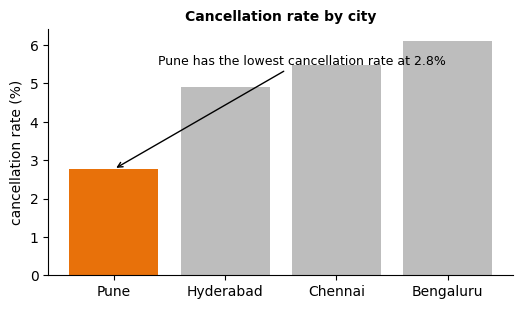

In [27]:
rate = df.groupby("city")["cancelled"].mean().sort_values() * 100
answer = rate.index[0]

def bar_colors(labels, answer):
    return [ACCENT if str(lbl) == str(answer) else GREY for lbl in labels]

annotation = f"{answer} has the lowest cancellation rate at {rate.iloc[0]:.1f}%"

colors = bar_colors(list(rate.index), answer)
assert colors.count(ACCENT) == 1 and colors.count(GREY) == len(rate) - 1
assert answer in annotation, "name the answer city in the annotation"

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(rate.index, rate.values, color=colors)
ax.annotate(annotation, xy=(0, rate.iloc[0]), xytext=(0.4, rate.max() * 0.9),
            arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_ylabel("cancellation rate (%)"); ax.set_title("Cancellation rate by city")
plt.show()

---
## Case 6 · Post-mortem: what went wrong in the pilot? (benefits, failure modes, the nested model, mitigations)
Six incidents were reported during the pilot.

| # | Incident |
|---|---|
| I1 | The manager asked for *average* fare per city. The chart's title says "Average", but the bars are **totals**, so Bengaluru (most rides) wins. |
| I2 | After *"only 2025"*, the follow-up *"what about cancellations?"* was drawn for **all years**, with no warning. |
| I3 | A chart was drawn of `driver_score`, a column that **does not exist**; the tool quietly filled it with random numbers. |
| I4 | A **line** was drawn connecting Auto, Mini, Sedan and Bike for *"compare average fare by vehicle type"*. |
| I5 | Bars comparing cancellation rates of 4.1 % and 4.4 % started the y-axis at 4 %, making one city look **twice as bad**. |
| I6 | The caption under a scatter plot read *"Surge pricing **causes** cancellations."* |

### 6a · Classify
**(i)** Label each incident with exactly one failure mode from `FAILURE_MODES`.
**(ii)** Place each statement in the right level of **Munzner's nested model** (`"domain"`, `"abstraction"`, `"idiom"`, `"algorithm"`).
**(iii)** Pick the best **mitigation** for each situation from `MITIGATIONS`.

* **L1.** The code crashes with a `KeyError`.
* **L2.** The tool answers a *trend* question when the analyst actually needed to *compare two groups*.
* **L3.** A 12-slice pie is used to compare ride counts.
* **L4.** Finance defines "revenue" net of driver incentives, but the tool uses gross fares.

Mitigation situations: **M1** — follow-ups silently drop filters (I2). **M2** — the tool keeps choosing pies and truncated axes (I4/I5). **M3** — a wrong aggregation slips through while the chart runs fine (I1). **M4** — a chart is about to go into the **board report**.

In [28]:
FAILURE_MODES = ["hallucinated field", "wrong aggregation / filter", "wrong chart for the task", "misleading design", "context drift", "over-confident narrative"]
LEVELS = ["domain", "abstraction", "idiom", "algorithm"]
MITIGATIONS = ["echo the interpretation", "make choices editable", "validate before showing", "keep the spec / code", "constrain the design", "human review for decisions"]

In [29]:
failure_mode = {
    "I1": "wrong aggregation / filter",       # title says average, bars are totals
    "I2": "context drift",                    # "only 2025" dropped on the follow-up
    "I3": "hallucinated field",               # driver_score invented, filled with random numbers
    "I4": "wrong chart for the task",         # line on nominal Auto/Mini/Sedan/Bike
    "I5": "misleading design",                # truncated y-axis exaggerates 4.1 vs 4.4
    "I6": "over-confident narrative",         # "causes" from a correlation scatter
}

nested_level = {
    "L1": "algorithm",     # KeyError = execution / code-level failure
    "L2": "abstraction",   # trend answered when compare was needed
    "L3": "idiom",         # 12-slice pie for comparing counts
    "L4": "domain",        # "revenue" net vs gross = data-definition mismatch
}

mitigation = {
    "M1": "keep the spec / code",             # filters dropped across turns → retain dialogue state
    "M2": "constrain the design",             # recurring pies / truncated axes → design rules
    "M3": "validate before showing",          # wrong aggregation runs fine → sanity check pre-render
    "M4": "human review for decisions",       # board-report chart → sign-off before publishing
}

assert all(v in FAILURE_MODES for v in failure_mode.values()), "failure_mode: choose from FAILURE_MODES"
assert all(v in LEVELS for v in nested_level.values()), "nested_level: choose from LEVELS"
assert all(v in MITIGATIONS for v in mitigation.values()), "mitigation: choose from MITIGATIONS"

print("failure modes :", failure_mode)
print("nested levels :", nested_level)
print("mitigations   :", mitigation)

failure modes : {'I1': 'wrong aggregation / filter', 'I2': 'context drift', 'I3': 'hallucinated field', 'I4': 'wrong chart for the task', 'I5': 'misleading design', 'I6': 'over-confident narrative'}
nested levels : {'L1': 'algorithm', 'L2': 'abstraction', 'L3': 'idiom', 'L4': 'domain'}
mitigations   : {'M1': 'keep the spec / code', 'M2': 'constrain the design', 'M3': 'validate before showing', 'M4': 'human review for decisions'}


### 6b · Your recommendation
Incident **I1** looked perfectly fine on screen and was only noticed because a manager happened to check the numbers. In two or three sentences: **which level of the nested model do the costliest errors live at, why are they dangerous,
and what should SwiftBite-style rollout rules require before ChatViz goes to every analyst?** *(Use RideNow in your answer.)*

### Reflection: rollout priorities and safeguards

14. What safeguards are needed when a visualization could expose sensitive operational information, such as driver performance or neighborhood-level demand?
Charts exposing driver performance or neighborhood-level demand need: access control and role-scoping (aggregate-only views for analysts outside HR/ops; individual driver metrics restricted and audited), disclosure limits (suppress or coarsen small cells — e.g., neighborhoods with < N drivers/rides — to prevent re-identification), no raw PII in prompts or specs (send only schema/aggregates to the LLM, never driver names or exact coordinates), audit logging of who queried what, and a review gate for anything exported externally. The lecture's point: the risk isn't just a wrong chart — it's a correct chart that leaks someone's data or enables discriminatory decisions.




15. After auditing ChatViz, what is the single most important improvement you would prioritize, and why?

Intent-faithfulness validation before rendering — a check that compares the generated spec's aggregation, filters, and measure to the parsed question and echoes the interpretation on-screen, refusing (or flagging) any mismatch. I'd prioritize it because it is the one safeguard that catches the costliest, quietest errors across the whole audit: I1 (wrong aggregation), I2 (dropped filter), and the exec-but-not-exact cases from 4b (Q3/Q6) — all of which pass execution accuracy and look fine to the user. Field validation (I3) and design rules (I4/I5) fix specific failure classes, but intent validation is the general gate that turns the pilot's "silent but plausible" regime into "wrong charts are caught before anyone trusts them," which is exactly the property that determines whether ChatViz is safe to deploy.




In [30]:
final_recommendation = (
    "The costliest errors live at the outer levels of the nested model — domain and abstraction — "
    "because a spec can pass every inner check (algorithm, idiom) and still answer the wrong question "
    "with the wrong meaning; I1 is exactly this: the chart rendered cleanly and the code ran fine, but a "
    "sum masqueraded as an average, an abstraction-layer failure no execution check can catch and that "
    "only a human happened to notice. These are dangerous because they are silent and plausible — the "
    "chart looks trustworthy, so analysts act on it — whereas a KeyError (algorithm level) is loud and "
    "harmless by comparison. Before ChatViz goes to every RideNow analyst, rollout should require "
    "intent-faithfulness validation before showing (aggregate and filters compared to the parsed question, "
    "with the interpretation echoed on-screen), a visible scope badge (active filters/aggregation) so "
    "silent drift is exposed, and a human sign-off gate for high-stakes outputs like board or regulator "
    "reports — the same SwiftBite-style rule that no chart with a semantic check failure reaches a "
    "decision-maker unreviewed."
)

---
### Before you finish
Run the cell below to see whether any answer has been left blank.

In [34]:
_required = ["abstract_tasks", "ambiguity_strategy", "turn_types", "transitions", "session_6_turns", "session_6_better", "turns_below_half",
             "prompt_fix", "exact_match_rate", "execution_accuracy", "component_acc", "ea_not_em", "annotation",
             "failure_mode", "nested_level", "mitigation", "final_recommendation"]
_blank = []
for _name in _required:
    _v = globals().get(_name)
    if _v is None or (isinstance(_v, str) and not _v.strip()) or (isinstance(_v, dict) and any(x is None for x in _v.values())):
        _blank.append(_name)
print("All answers filled in." if not _blank else "Still blank: " + ", ".join(_blank))

All answers filled in.
